In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
uproot.__version__, pd.__version__, np.__version__, xgboost.__version__

('4.3.7', '1.5.3', '1.23.5', '2.0.2')

In [3]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [25]:
mplhep.style.use('ATLAS')
nbins = 10

In [5]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [6]:
# Set of variables for WP85

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets85', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb85_closest[:,0]',
                'ph_mphb85_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 1 times.


In [7]:
len(feature_cols)

20

In [8]:
cols = feature_cols+['eventNumber','weight']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [9]:
df_sig_85 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets85>=1)',library="pd",aliases=aliases)


In [10]:
# not needed rn
df_bkg_prompt_tot_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model//ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
#df_bkg_prompt_tty = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model//ntuples_WP85/*ttgamma_*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
#df_bkg_prompt_Vyy = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)


In [11]:
#not needed rn
df_bkg_fakes_tot_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model//ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
#df_bkg_fakes_tty = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model//ntuples_WP85/*ttgamma_*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
#df_bkg_fakes_Vyy = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)


In [12]:
# Reweight the background datasets 
#Fakes: 3051 (85) -> 0.89* 2726 (70)
#Prompts: 2804 (85) -> 0.44 * 1233 (70)
df_bkg_prompt_tot_85['weight'] *= 0.4397  # Apply scaling for prompt background
df_bkg_fakes_tot_85['weight'] *= 0.8935  # Apply scaling for fake background


In [13]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_85_reweighted = pd.concat([df_bkg_prompt_tot_85, df_bkg_fakes_tot_85], ignore_index=True)


In [14]:
len(df_sig_85), len(df_bkg_85), len(df_bkg_85_reweighted) #, len(df_bkg_prompt_tot), len(df_bkg_fakes_tot)
# WP 70: 323900, 3959 

(358887, 5855, 5855)

In [15]:
df_sig_70 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [16]:
len(df_sig_70), len(df_bkg_70)

(323900, 3959)

In [15]:
# just a check, no need to run!!!!
print(df_bkg['ph_true_category'].head())
print(type(df_bkg['ph_true_category'].iloc[0]))

0    10
1     2
2     6
3     2
4    10
Name: ph_true_category, dtype: int32
<class 'numpy.int32'>


# Training and Evaluation with WP85

In [17]:
n_estimators = 100

In [18]:
# SINGLE MODEL  : Using XGB Classifier
# with WP85 and NOT reweighted to WP70
models_85 = []
nfolds = 4
scores_train,scores_test = [],[]
testloss_85 = {fold:[] for fold in range(nfolds)}
trainloss_85 = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    print("-------------------------------------------------------------------------------")
    print(f'Doing it for fold: {fold}')
    X_sig_train = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85[feature_cols][df_sig_85['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85['weight'][df_sig_85['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg_85[feature_cols][df_bkg_85['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg_85['weight'][df_bkg_85['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg_85[feature_cols][df_bkg_85['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg_85['weight'][df_bkg_85['eventNumber']%nfolds == fold]
    
    print('Length of training and testing datasets loaded:')
    print(f'Signal training stats: {len(X_sig_train)}')
    print(f'Background training stats: {len(X_bkg_train)}')
    
    print(f'Signal testing stats: {len(X_sig_test)}')
    print(f'Background testing stats: {len(X_bkg_test)}')
    
    
    # Setting up the concatentated datasets for training and testing
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print('Total datasets:')
    print(f'Signal+Background training: {len(X_train)}')
    print(f'Signal+Background testing: {len(X_test)}')
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    
    # Note: No scale_pos_weight reweighting being used
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models_85.append(model)
    print(f'Model {fold}:', models_85[fold])
    
    #Calculating scores
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test))) 
    print(f'Training scores {fold}:', scores_train)
    print(f'Testing scores {fold}:', scores_test)
       
                       
    #For loss curve
    n_boosters = len(models_85[fold].get_booster().get_dump(dump_format='json'))
    print('Number of boosters in the model:', n_boosters)
    for i in range(n_boosters):
        # ypred contains the predicted probabilities of class 1 (positive class i.e. [:,1]) for all samples in X_train, based on the model trained on the specified iteration range of 1 till i+1 estimators/boosters 
        ypred = models_85[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss_85[fold].append(loss)
        # similarly for testing
        ypred = models_85[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss_85[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP85_Model{execution_count}_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

-------------------------------------------------------------------------------
Doing it for fold: 0
Length of training and testing datasets loaded:
Signal training stats: 269250
Background training stats: 4403
Signal testing stats: 89637
Background testing stats: 1452
Total datasets:
Signal+Background training: 273653
Signal+Background testing: 91089
Model 0: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
        

In [19]:
mplhep.style.use('ATLAS')

In [20]:
# Some loss curve related checks:
loss_fold = 0 # can be [0,1,2,3]
#print(trainloss) # all the loss values for all the estimators and all the folds
print(len(trainloss_85)) # length of 4
print(trainloss_85[loss_fold])
print(len(trainloss_85[loss_fold]))
print(trainloss_85[loss_fold][0:10])
print(trainloss_85[loss_fold][-1])


4
[0.7139577978227799, 0.691306646393313, 0.6749346174684177, 0.6604491801536609, 0.6522804042617623, 0.646090710932034, 0.6390014971803197, 0.6327595497421972, 0.6285409826711856, 0.6249020652583864, 0.6198896725494993, 0.618386525525926, 0.613615636955357, 0.6106429849587102, 0.6072812055091852, 0.6040583899167539, 0.603436986034679, 0.6009017170755934, 0.5983514183979978, 0.5965805059816551, 0.594931227750834, 0.593013212914276, 0.5906051424345786, 0.590291631975025, 0.5885617179613131, 0.5862060277775455, 0.5850902031457041, 0.5839145523837804, 0.582453885881652, 0.5815176018911737, 0.5805733445695117, 0.5787922213078452, 0.5771139001768907, 0.5761895795889804, 0.5748545327351466, 0.5734241488048104, 0.5727023504195564, 0.5718917765855426, 0.5707224086390156, 0.5697373146567511, 0.5691934834185902, 0.568275986750897, 0.5678755114042701, 0.5668430883945896, 0.5657512758958664, 0.5646955374554813, 0.5638609499640468, 0.5634947711288208, 0.5623255137172691, 0.5616460491064734, 0.56073

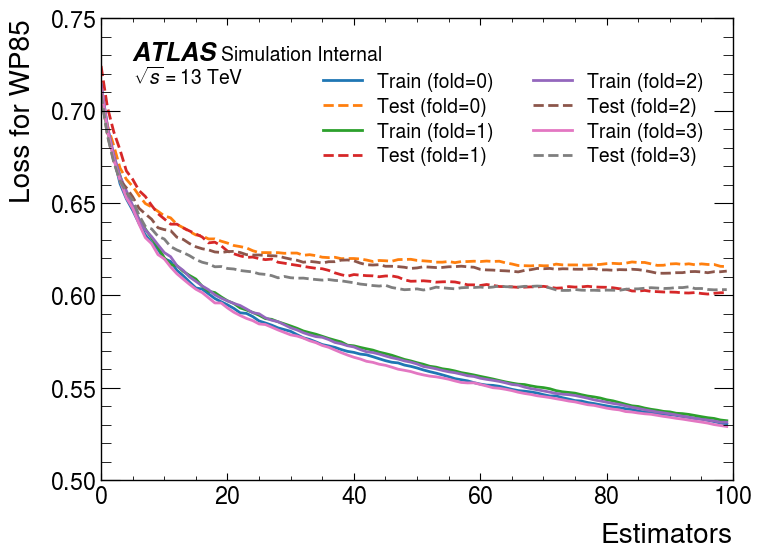

In [26]:
    
# Plotting the results For WP85 only
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss_85[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss_85[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2)
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss for WP85')
#plt.savefig(f'loss_curve.pdf')

plt.show()

In [27]:
X_sig_85 = df_sig_85[feature_cols].to_numpy().astype(np.float32) 
X_bkg_85 = df_bkg_85[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig_85)[:,1] for model in models_85]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg_85)[:,1] for model in models_85]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig_85['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig_85 = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg_85['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_85 = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig_85, results_bkg_85
print("Length sig: ", len(results_sig_85))
print("Length bkg: ", len(results_bkg_85))

Arrays for BDT scroes:
Sig:  [array([0.51949185, 0.6383609 , 0.7180131 , ..., 0.7339629 , 0.7771796 ,
       0.5389605 ], dtype=float32), array([0.56396633, 0.5911795 , 0.7326335 , ..., 0.72809094, 0.7195093 ,
       0.46064162], dtype=float32), array([0.48828992, 0.6955217 , 0.6916631 , ..., 0.76824546, 0.6183214 ,
       0.6238853 ], dtype=float32), array([0.46608007, 0.5842363 , 0.6919366 , ..., 0.7256135 , 0.7530754 ,
       0.6193473 ], dtype=float32)]
Bkg:  [array([0.3583942 , 0.49710447, 0.79023635, ..., 0.15175329, 0.43322104,
       0.10948578], dtype=float32), array([0.32352176, 0.46794915, 0.72822434, ..., 0.15816088, 0.62862676,
       0.11445035], dtype=float32), array([0.29478496, 0.584455  , 0.62510806, ..., 0.14986554, 0.44511864,
       0.1104516 ], dtype=float32), array([0.27803603, 0.6139644 , 0.77051574, ..., 0.2322155 , 0.50655186,
       0.0940142 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  358887
Length bkg:  5855


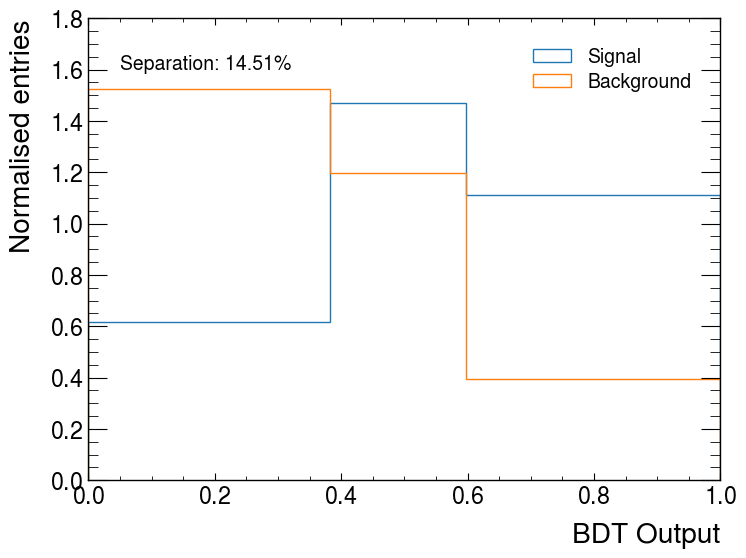

In [28]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig_85, weights=df_sig_85['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg_85, weights=df_bkg_85['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


Data saved to 'roc_data_85.npz'


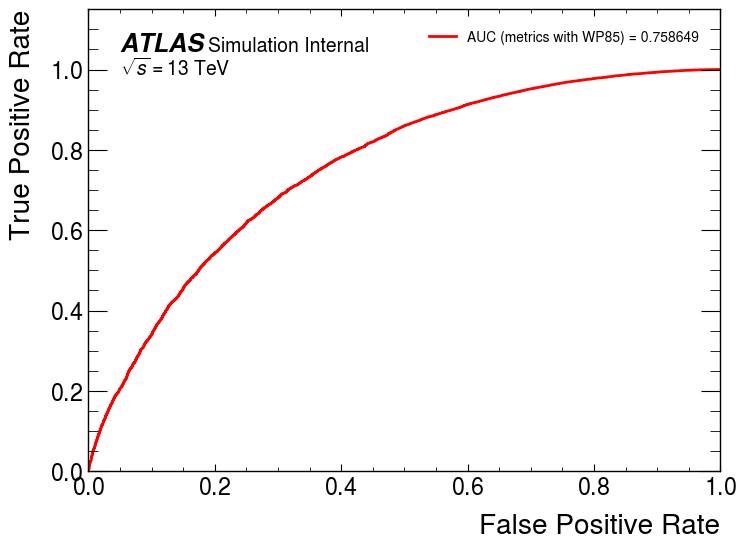

In [29]:
# Aggregate AUC 

scores_85 = np.concatenate([results_sig_85, results_bkg_85])
y_85 = np.concatenate([np.ones_like(results_sig_85), np.zeros_like(results_bkg_85)])

fpr_85, tpr_85, thresholds_85 = metrics.roc_curve(y_85, scores_85, pos_label=1)
AUC_85 = metrics.roc_auc_score(y_85, scores_85)

plt.plot(fpr_85,tpr_85,label=F'AUC (metrics with WP85) = {AUC_85:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

# Save the data to a file
np.savez('roc_data_85.npz', fpr=fpr_85, tpr=tpr_85, thresholds=thresholds_85, auc=AUC_85)
print("Data saved to 'roc_data_85.npz'")

##############################################################################################################

# Training and Evaluation with WP85 (bkg reweighted to match WP70 statistics)

In [30]:
df_sig_85_reweighted = df_sig_85

In [31]:
# SINGLE MODEL  : Using XGB Classifier
# with WP85 and NOT reweighted to WP70
models_85_reweighted = []
nfolds = 4
scores_train,scores_test = [],[]
testloss_85_reweighted = {fold:[] for fold in range(nfolds)}
trainloss_85_reweighted = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    print("-------------------------------------------------------------------------------")
    print(f'Doing it for fold: {fold}')
    X_sig_train = df_sig_85_reweighted[feature_cols][df_sig_85_reweighted['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85_reweighted[feature_cols][df_sig_85_reweighted['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg_85_reweighted[feature_cols][df_bkg_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg_85_reweighted[feature_cols][df_bkg_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%nfolds == fold]
    
    print('Length of training and testing datasets loaded:')
    print(f'Signal training stats: {len(X_sig_train)}')
    print(f'Background training stats: {len(X_bkg_train)}')
    
    print(f'Signal testing stats: {len(X_sig_test)}')
    print(f'Background testing stats: {len(X_bkg_test)}')
    
    
    # Setting up the concatentated datasets for training and testing
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print('Total datasets:')
    print(f'Signal+Background training: {len(X_train)}')
    print(f'Signal+Background testing: {len(X_test)}')
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    
    # Note: No scale_pos_weight reweighting being used
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models_85_reweighted.append(model)
    print(f'Model {fold}:', models_85_reweighted[fold])
    
    #Calculating scores
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test))) 
    print(f'Training scores {fold}:', scores_train)
    print(f'Testing scores {fold}:', scores_test)
       
                       
    #For loss curve
    n_boosters = len(models_85_reweighted[fold].get_booster().get_dump(dump_format='json'))
    print('Number of boosters in the model:', n_boosters)
    for i in range(n_boosters):
        # ypred contains the predicted probabilities of class 1 (positive class i.e. [:,1]) for all samples in X_train, based on the model trained on the specified iteration range of 1 till i+1 estimators/boosters 
        ypred = models_85_reweighted[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss_85_reweighted[fold].append(loss)
        # similarly for testing
        ypred = models_85_reweighted[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss_85_reweighted[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP85_Model{execution_count}_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

-------------------------------------------------------------------------------
Doing it for fold: 0
Length of training and testing datasets loaded:
Signal training stats: 269250
Background training stats: 4403
Signal testing stats: 89637
Background testing stats: 1452
Total datasets:
Signal+Background training: 273653
Signal+Background testing: 91089
Model 0: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
        

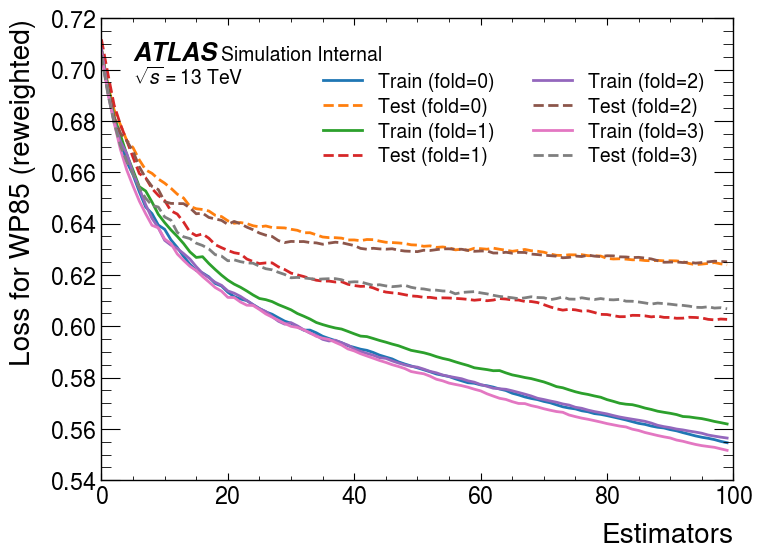

In [32]:
    
    
# Plotting the results For WP85 only
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss_85_reweighted[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss_85_reweighted[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2)
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss for WP85 (reweighted)')
#plt.savefig(f'loss_curve.pdf')

plt.show()

In [33]:
X_sig_85_reweighted = df_sig_85_reweighted[feature_cols].to_numpy().astype(np.float32) 
X_bkg_85_reweighted = df_bkg_85_reweighted[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = []
results_bkg_list = []

results_sig_list = [model.predict_proba(X_sig_85_reweighted)[:,1] for model in models_85_reweighted]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg_85_reweighted)[:,1] for model in models_85_reweighted]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig_85_reweighted = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_85_reweighted = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig_85_reweighted, results_bkg_85_reweighted
print("Length sig: ", len(results_sig_85_reweighted))
print("Length bkg: ", len(results_bkg_85_reweighted))

Arrays for BDT scroes:
Sig:  [array([0.51667076, 0.6738051 , 0.7780718 , ..., 0.7640088 , 0.8002035 ,
       0.66349405], dtype=float32), array([0.5840913 , 0.6215645 , 0.76265347, ..., 0.7562711 , 0.75030875,
       0.63200617], dtype=float32), array([0.5487538 , 0.6918187 , 0.7783714 , ..., 0.7999068 , 0.72517943,
       0.6798858 ], dtype=float32), array([0.5499057 , 0.5865603 , 0.74815583, ..., 0.7077958 , 0.74111265,
       0.705335  ], dtype=float32)]
Bkg:  [array([0.6347501 , 0.2643699 , 0.1782032 , ..., 0.2984693 , 0.28631797,
       0.2547088 ], dtype=float32), array([0.507073  , 0.24675797, 0.1868626 , ..., 0.45302972, 0.27526394,
       0.17291223], dtype=float32), array([0.6055557 , 0.3484304 , 0.22602423, ..., 0.38541356, 0.29100144,
       0.23083103], dtype=float32), array([0.60926723, 0.28075054, 0.20210648, ..., 0.3473413 , 0.25368947,
       0.25292987], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  358887
Length bkg:  5855


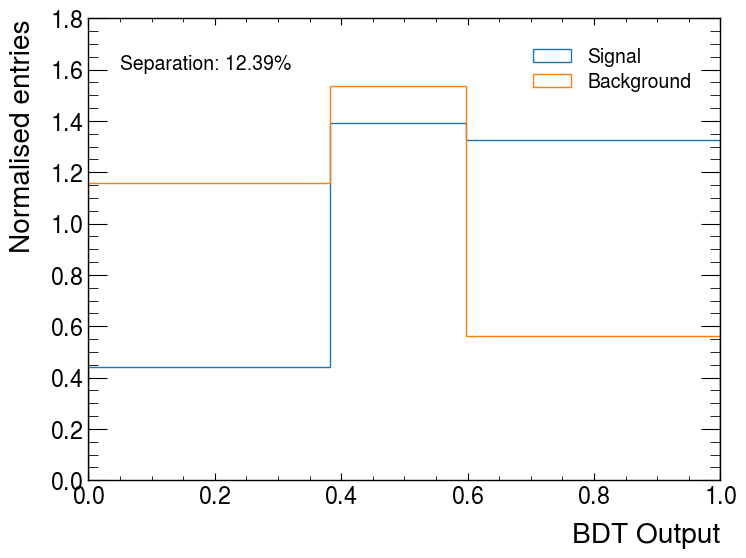

In [34]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig_85_reweighted, weights=df_sig_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg_85_reweighted, weights=df_bkg_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


Data saved to 'roc_data_85_reweighted.npz'


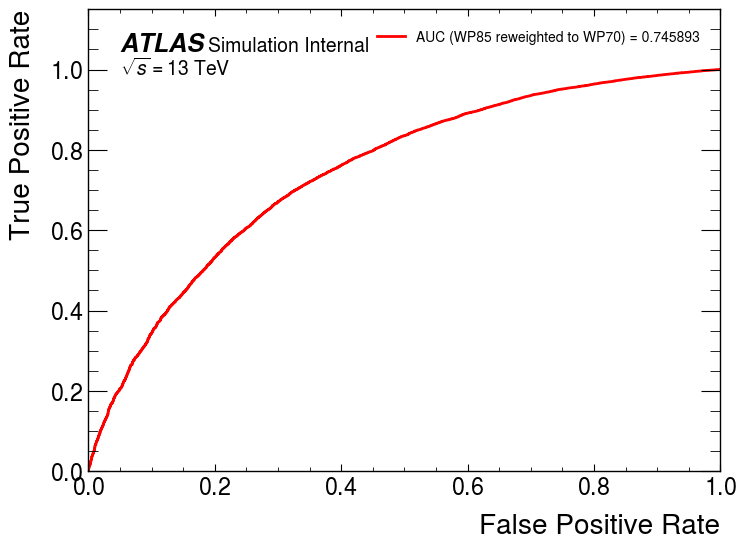

In [36]:
# Aggregate AUC 

scores_85_reweighted = np.concatenate([results_sig_85_reweighted, results_bkg_85_reweighted])
y_85_reweighted = np.concatenate([np.ones_like(results_sig_85_reweighted), np.zeros_like(results_bkg_85_reweighted)])

fpr_85_reweighted, tpr_85_reweighted, thresholds_85_reweighted = metrics.roc_curve(y_85_reweighted, scores_85_reweighted, pos_label=1)
AUC_85_reweighted = metrics.roc_auc_score(y_85_reweighted, scores_85_reweighted)

plt.plot(fpr_85_reweighted,tpr_85_reweighted,label=F'AUC (WP85 reweighted to WP70) = {AUC_85_reweighted:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

# Save the data to a file
np.savez('roc_data_85_reweighted.npz', fpr=fpr_85_reweighted, tpr=tpr_85_reweighted, thresholds=thresholds_85_reweighted, auc=AUC_85_reweighted)
print("Data saved to 'roc_data_85_reweighted.npz'")

######################################################################################################################################

# Training and Evaluation with WP70 

## Redo training because of changed feature_cols OR try to use the npz file as it has stored AUC values from WP70 run on different ipynb file

In [ ]:
# Need to change set of feature cols

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets70', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb70_closest[:,0]',
                'ph_mphb70_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


In [9]:
df_sig_70 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/new_ntuples_24052024/PCBT_/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [11]:
n_estimators = 100

In [13]:
# SINGLE MODEL  : Using XGB Classifier
# with WP70 
models_70 = []
nfolds = 4
scores_train,scores_test = [],[]
testloss_70 = {fold:[] for fold in range(nfolds)}
trainloss_70 = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    print("-------------------------------------------------------------------------------")
    print(f'Doing it for fold: {fold}')
    X_sig_train = df_sig_70[feature_cols][df_sig_70['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_70['weight'][df_sig_70['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_70[feature_cols][df_sig_70['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_70['weight'][df_sig_70['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg_70[feature_cols][df_bkg_70['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg_70['weight'][df_bkg_70['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg_70[feature_cols][df_bkg_70['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg_70['weight'][df_bkg_70['eventNumber']%nfolds == fold]
    
    print('Length of training and testing datasets loaded:')
    print(f'Signal training stats: {len(X_sig_train)}')
    print(f'Background training stats: {len(X_bkg_train)}')
    
    print(f'Signal testing stats: {len(X_sig_test)}')
    print(f'Background testing stats: {len(X_bkg_test)}')
    
    
    # Setting up the concatentated datasets for training and testing
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print('Total datasets:')
    print(f'Signal+Background training: {len(X_train)}')
    print(f'Signal+Background testing: {len(X_test)}')
    print('training predictions: ',len(y_train) )
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    
    # Note: No scale_pos_weight reweighting being used
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models_70.append(model)
    print(f'Model {fold}:', models_70[fold])
    
    #Calculating scores
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test))) 
    print(f'Training scores {fold}:', scores_train)
    print(f'Testing scores {fold}:', scores_test)
       
                       
    #For loss curve
    n_boosters = len(models_70[fold].get_booster().get_dump(dump_format='json'))
    print('Number of boosters in the model:', n_boosters)
    for i in range(n_boosters):
        # ypred contains the predicted probabilities of class 1 (positive class i.e. [:,1]) for all samples in X_train, based on the model trained on the specified iteration range of 1 till i+1 estimators/boosters 
        ypred = models_70[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss_70[fold].append(loss)
        # similarly for testing
        ypred = models_70[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss_70[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP85_Model{execution_count}_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

-------------------------------------------------------------------------------
Doing it for fold: 0
Length of training and testing datasets loaded:
Signal training stats: 243054
Background training stats: 2977
Signal testing stats: 80846
Background testing stats: 982
Total datasets:
Signal+Background training: 246031
Signal+Background testing: 81828
training predictions:  246031
Model 0: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monoto

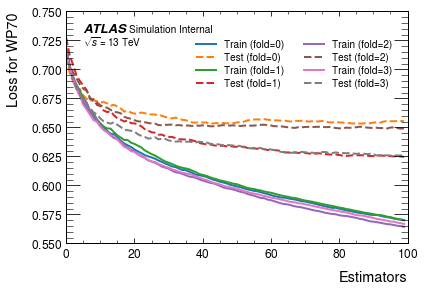

In [14]:
    
# Plotting the results For WP85 only
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss_70[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss_70[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2)
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss for WP70')
#plt.savefig(f'loss_curve.pdf')

plt.show()

In [97]:
# Using WP85 model to produce results for WP70
fold = 0
nfolds = 4
X_sig_70 = df_sig_70[feature_cols].to_numpy().astype(np.float32) 
X_bkg_70 = df_bkg_70[feature_cols].to_numpy().astype(np.float32) 

print('Length of signal dataset for which predictions need to be made:', len(X_sig_70))
print('Length of background dataset for which predictions need to be made:', len(X_bkg_70))


results_sig_list_70 = [model.predict_proba(X_sig_70)[:,1] for model in models_70]   #array of bdt scores
results_bkg_list_70 = [model.predict_proba(X_bkg_70)[:,1] for model in models_70]   #array of bdt scores
print("----------------------------------------------")
print('\nArrays for BDT scores for 4 models:')
print(f'Sig for fold {fold}: ',results_sig_list_70[0])
print(f'Length of signal predictions for fold {fold}:',len(results_sig_list_70[0]) )
print(f'Length of bkg predictions for fold {fold}:',len(results_bkg_list_70[0]) )
print(f'\nSig for all folds: ',results_sig_list_70)
print('\nBkg for all folds: ',results_bkg_list_70)
print("----------------------------------------------")



# Separate into folds
condlist_sig = [df_sig_70['eventNumber']%nfolds == fold for fold in range(nfolds)]
print('Conditional list length for signal dataset:', len(condlist_sig))
fold = 0
print(f'Conditional list length for signal dataset for fold {fold}:', len(condlist_sig[fold]))
print(condlist_sig[1])
#print(condlist_sig[0][0:10], condlist_sig[1][0:10], condlist_sig[2][0:10], condlist_sig[3][0:10])
# Print condlist_sig values side by side for the first 10 entries
for row in zip(condlist_sig[0][:10], condlist_sig[1][:10], condlist_sig[2][:10], condlist_sig[3][:10]):
    print(row)


results_sig_70 = np.select(condlist_sig, results_sig_list_70)

condlist_bkg = [df_bkg_70['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_70 = np.select(condlist_bkg, results_bkg_list_70)

print('Fold separated arrays for BDT scores:')
print(results_sig_70, results_bkg_70)
print("Length sig: ", len(results_sig_70))
print("Length bkg: ", len(results_bkg_70))

Length of signal dataset for which predictions need to be made: 323900
Length of background dataset for which predictions need to be made: 3959
----------------------------------------------

Arrays for BDT scores for 4 models:
Sig for fold 0:  [0.54758465 0.4671587  0.71962106 ... 0.7235317  0.69277006 0.6047411 ]
Length of signal predictions for fold 0: 323900
Length of bkg predictions for fold 0: 3959

Sig for all folds:  [array([0.54758465, 0.4671587 , 0.71962106, ..., 0.7235317 , 0.69277006,
       0.6047411 ], dtype=float32), array([0.54998416, 0.61055106, 0.7220157 , ..., 0.68441916, 0.74094975,
       0.5054421 ], dtype=float32), array([0.61022395, 0.7045106 , 0.76845497, ..., 0.7299155 , 0.757547  ,
       0.62606484], dtype=float32), array([0.4097317 , 0.5568563 , 0.71028084, ..., 0.650292  , 0.78427845,
       0.69780546], dtype=float32)]

Bkg for all folds:  [array([0.44925338, 0.50934124, 0.79445523, ..., 0.64445156, 0.26418495,
       0.77502364], dtype=float32), array([0

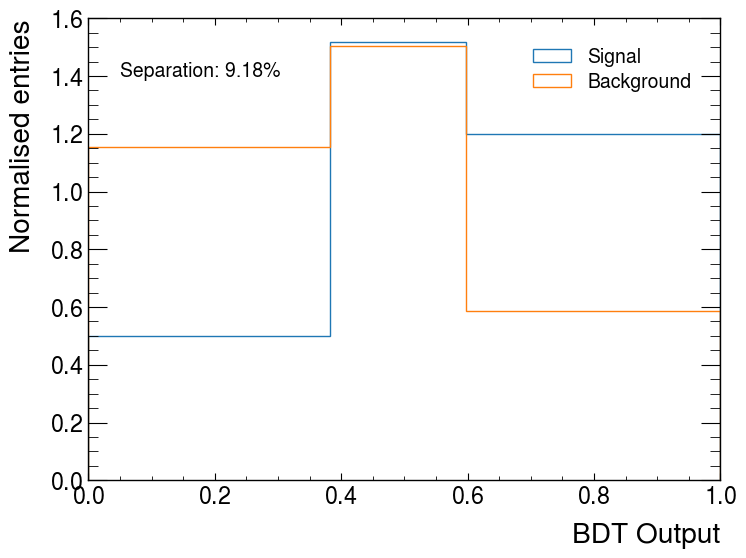

In [98]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig_70, weights=df_sig_70['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg_70, weights=df_bkg_70['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

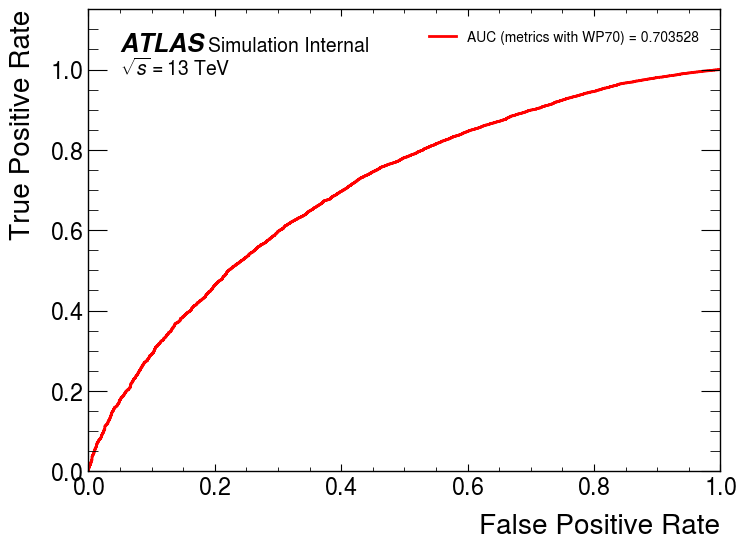

In [100]:
# Aggregate AUC 

scores_70 = np.concatenate([results_sig_70, results_bkg_70])
y_70 = np.concatenate([np.ones_like(results_sig_70), np.zeros_like(results_bkg_70)])

fpr_70, tpr_70, thresholds_70 = metrics.roc_curve(y_70, scores_70, pos_label=1)
AUC_70 = metrics.roc_auc_score(y_70, scores_70)

plt.plot(fpr_70,tpr_70,label=F'AUC (metrics with WP70) = {AUC_70:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

In [16]:
data = np.load('roc_data_70.npz')
fpr_70 = data['fpr']
tpr_70 = data['tpr']
thresholds_70 = data['thresholds']
AUC_70 = data['auc']
print(f"Loaded data: AUC = {AUC_70}")

Loaded data: AUC = 0.6948133504263093


# All in one AUC

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

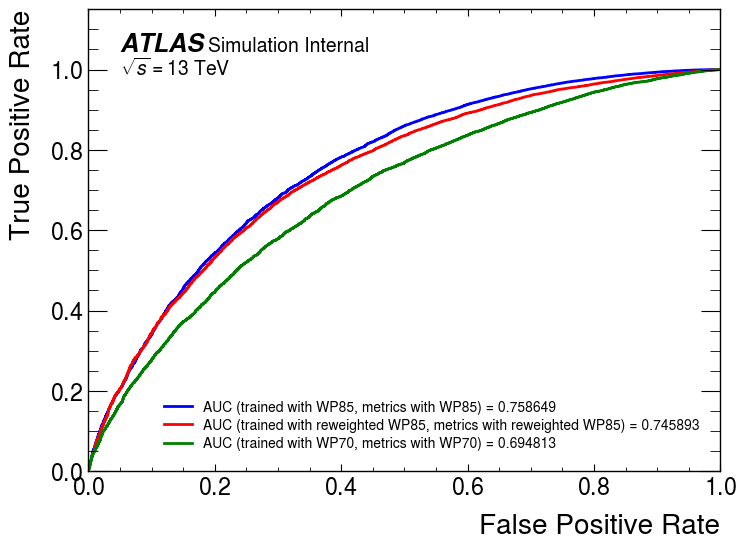

In [45]:
# AUC's comparison:


plt.plot(fpr_85,tpr_85,label=F'AUC (trained with WP85, metrics with WP85) = {AUC_85:.6f}', color='blue')
plt.plot(fpr_85_reweighted,tpr_85_reweighted,label=F'AUC (trained with reweighted WP85, metrics with reweighted WP85) = {AUC_85_reweighted:.6f}', color='red')
plt.plot(fpr_70,tpr_70,label=F'AUC (trained with WP70, metrics with WP70) = {AUC_70:.6f}', color='green')


plt.legend(loc = 'lower right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

# !!!! Don't touch Below right now   !!!!!!!

# BEWARE!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! BEWARE!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! BEWARE!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

# ##############################

# ##############################

In [37]:
# SINGLE MODEL  : Using XGB Classifier
models = []
nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    print("-------------------------------------------------------------------------------")
    print(f'Doing it for fold: {fold}')
    X_sig_train = df_sig[feature_cols][df_sig['eventNumber']%nfolds != fold]
    w_sig_train = df_sig['weight'][df_sig['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig[feature_cols][df_sig['eventNumber']%nfolds == fold]
    w_sig_test = df_sig['weight'][df_sig['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg['weight'][df_bkg['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg[feature_cols][df_bkg['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg['weight'][df_bkg['eventNumber']%nfolds == fold]
    
    print('Length of training and testing datasets loaded:')
    print(f'Signal training stats: {len(X_sig_train)}')
    print(f'Background training stats: {len(X_bkg_train)}')
    
    print(f'Signal testing stats: {len(X_sig_test)}')
    print(f'Background testing stats: {len(X_bkg_test)}')
    
    
    # Setting up the concatentated datasets for training and testing
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print('Total datasets:')
    print(f'Signal+Background training: {len(X_train)}')
    print(f'Signal+Background testing: {len(X_test)}')
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    
    # Note: No scale_pos_weight reweighting being used
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models.append(model)
    print(f'Model {fold}:', models[fold])
    
    #Calculating scores
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test))) 
    print(f'Training scores {fold}:', scores_train)
    print(f'Testing scores {fold}:', scores_test)
       
                       
    #For loss curve
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print('Number of boosters in the model:', n_boosters)
    for i in range(n_boosters):
        # ypred contains the predicted probabilities of class 1 (positive class i.e. [:,1]) for all samples in X_train, based on the model trained on the specified iteration range of 1 till i+1 estimators/boosters 
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        # similarly for testing
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP85_Model{execution_count}_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

-------------------------------------------------------------------------------
Doing it for fold: 0
Length of training and testing datasets loaded:
Signal training stats: 269250
Background training stats: 4403
Signal testing stats: 89637
Background testing stats: 1452
Total datasets:
Signal+Background training: 273653
Signal+Background testing: 91089
Model 0: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
        

In [40]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig, results_bkg
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Arrays for BDT scroes:
Sig:  [array([0.51667076, 0.6738051 , 0.7780718 , ..., 0.7640088 , 0.8002035 ,
       0.66349405], dtype=float32), array([0.5840913 , 0.6215645 , 0.76265347, ..., 0.7562711 , 0.75030875,
       0.63200617], dtype=float32), array([0.5487538 , 0.6918187 , 0.7783714 , ..., 0.7999068 , 0.72517943,
       0.6798858 ], dtype=float32), array([0.5499057 , 0.5865603 , 0.74815583, ..., 0.7077958 , 0.74111265,
       0.705335  ], dtype=float32)]
Bkg:  [array([0.6347501 , 0.2643699 , 0.1782032 , ..., 0.2984693 , 0.28631797,
       0.2547088 ], dtype=float32), array([0.507073  , 0.24675797, 0.1868626 , ..., 0.45302972, 0.27526394,
       0.17291223], dtype=float32), array([0.6055557 , 0.3484304 , 0.22602423, ..., 0.38541356, 0.29100144,
       0.23083103], dtype=float32), array([0.60926723, 0.28075054, 0.20210648, ..., 0.3473413 , 0.25368947,
       0.25292987], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  358887
Length bkg:  5855


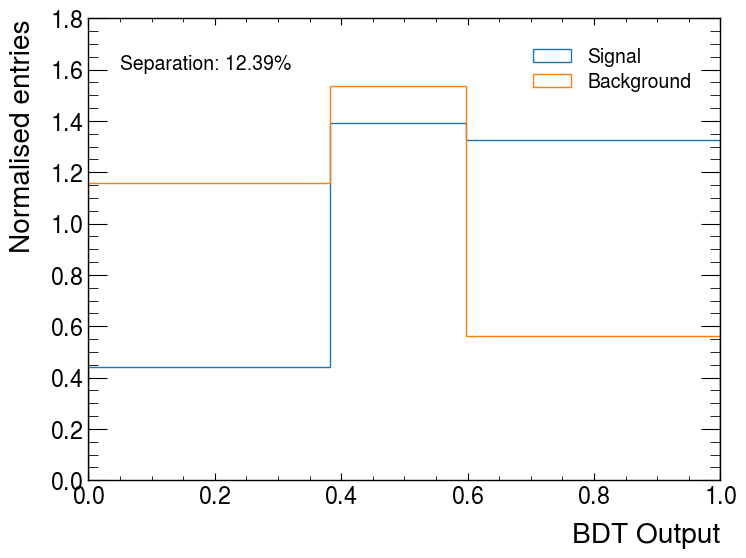

In [42]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


In [ ]:
# Aggregate AUC 

scores = np.concatenate([results_sig, results_bkg])
y = np.concatenate([np.ones_like(results_sig), np.zeros_like(results_bkg)])

fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
AUC = metrics.roc_auc_score(y, scores)

plt.plot(fpr,tpr,label=F'AUC (metrics with WP70) = {AUC:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

(323900, 3959)

In [93]:
# SINGLE MODEL  : Using XGB Classifier

nfolds = 4
scores_train,scores_test = [],[]
testloss = {fold:[] for fold in range(nfolds)}
trainloss = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    print("-------------------------------------------------------------------------------")
    print(f'Doing it for fold: {fold}')
    X_sig_train = df_sig_70[feature_cols][df_sig_70['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_70['weight'][df_sig_70['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_70[feature_cols][df_sig_70['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_70['weight'][df_sig_70['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg_70[feature_cols][df_bkg_70['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg_70['weight'][df_bkg_70['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg_70[feature_cols][df_bkg_70['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg_70['weight'][df_bkg_70['eventNumber']%nfolds == fold]
    
    print('Length of training and testing datasets loaded:')
    print(f'Signal training stats: {len(X_sig_train)}')
    print(f'Background training stats: {len(X_bkg_train)}')
    
    print(f'Signal testing stats: {len(X_sig_test)}')
    print(f'Background testing stats: {len(X_bkg_test)}')
    
    
    # Setting up the concatentated datasets for training and testing
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print('Total datasets:')
    print(f'Signal+Background training: {len(X_train)}')
    print(f'Signal+Background testing: {len(X_test)}')
    
                       
    #For loss curve
    n_boosters = len(models[fold].get_booster().get_dump(dump_format='json'))
    print('Number of boosters in the model:', n_boosters)
    for i in range(n_boosters):
        # ypred contains the predicted probabilities of class 1 (positive class i.e. [:,1]) for all samples in X_train, based on the model trained on the specified iteration range of 1 till i+1 estimators/boosters 
        ypred = models[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=w_train)
        trainloss[fold].append(loss)
        # similarly for testing
        ypred = models[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=w_test)
        testloss[fold].append(loss)
        

-------------------------------------------------------------------------------
Doing it for fold: 0
Length of training and testing datasets loaded:
Signal training stats: 243054
Background training stats: 2977
Signal testing stats: 80846
Background testing stats: 982
Total datasets:
Signal+Background training: 246031
Signal+Background testing: 81828
Number of boosters in the model: 100
-------------------------------------------------------------------------------
Doing it for fold: 1
Length of training and testing datasets loaded:
Signal training stats: 242986
Background training stats: 3009
Signal testing stats: 80914
Background testing stats: 950
Total datasets:
Signal+Background training: 245995
Signal+Background testing: 81864
Number of boosters in the model: 100
-------------------------------------------------------------------------------
Doing it for fold: 2
Length of training and testing datasets loaded:
Signal training stats: 242824
Background training stats: 2965
Signal te

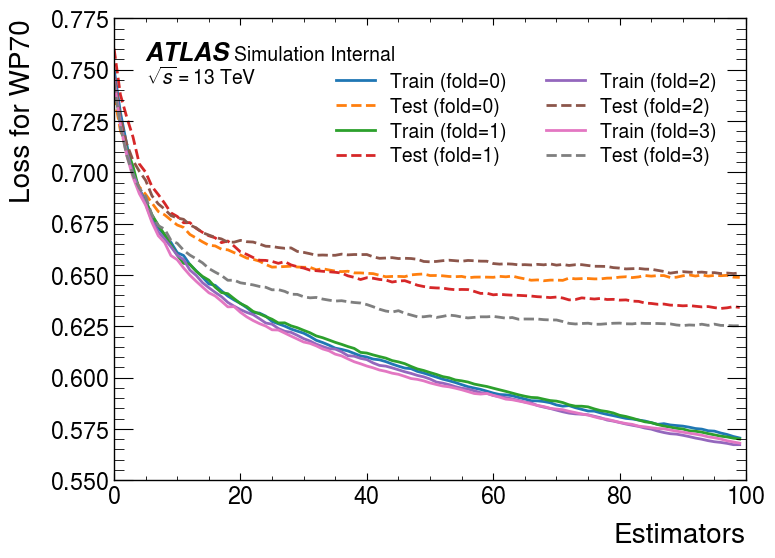

In [94]:
    
# Plotting the results For WP70 
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2)
ax.set_title('')
mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss for WP70')
#plt.savefig(f'loss_curve.pdf')

plt.show()

In [129]:
# Using WP85 model to produce results for WP70
fold = 0
nfolds = 4
X_sig = df_sig_70[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg_70[feature_cols].to_numpy().astype(np.float32) 

print('Length of signal dataset for which predictions need to be made:', len(X_sig))
print('Length of background dataset for which predictions need to be made:', len(X_bkg))


results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores
print("----------------------------------------------")
print('\nArrays for BDT scores for 4 models:')
print(f'Sig for fold {fold}: ',results_sig_list[0])
print(f'Length of signal predictions for fold {fold}:',len(results_sig_list[0]) )
print(f'Length of bkg predictions for fold {fold}:',len(results_bkg_list[0]) )
print(f'\nSig for all folds: ',results_sig_list)
print('\nBkg for all folds: ',results_bkg_list)
print("----------------------------------------------")



# Separate into folds
condlist_sig = [df_sig_70['eventNumber']%nfolds == fold for fold in range(nfolds)]
print('Conditional list length for signal dataset:', len(condlist_sig))
fold = 0
print(f'Conditional list length for signal dataset for fold {fold}:', len(condlist_sig[fold]))
print(condlist_sig[1])
#print(condlist_sig[0][0:10], condlist_sig[1][0:10], condlist_sig[2][0:10], condlist_sig[3][0:10])
# Print condlist_sig values side by side for the first 10 entries
for row in zip(condlist_sig[0][:10], condlist_sig[1][:10], condlist_sig[2][:10], condlist_sig[3][:10]):
    print(row)


results_sig = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg_70['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scores:')
print(results_sig, results_bkg)
print("Length sig: ", len(results_sig))
print("Length bkg: ", len(results_bkg))

Length of signal dataset for which predictions need to be made: 323900
Length of background dataset for which predictions need to be made: 3959
----------------------------------------------

Arrays for BDT scores for 4 models:
Sig for fold 0:  [0.51949185 0.6383609  0.7180131  ... 0.7339629  0.7771796  0.5389605 ]
Length of signal predictions for fold 0: 323900
Length of bkg predictions for fold 0: 3959

Sig for all folds:  [array([0.51949185, 0.6383609 , 0.7180131 , ..., 0.7339629 , 0.7771796 ,
       0.5389605 ], dtype=float32), array([0.56396633, 0.5911795 , 0.7326335 , ..., 0.72809094, 0.7195093 ,
       0.46064162], dtype=float32), array([0.48828992, 0.6955217 , 0.6916631 , ..., 0.76824546, 0.6183214 ,
       0.6238853 ], dtype=float32), array([0.46608007, 0.5842363 , 0.6919366 , ..., 0.7256135 , 0.7530754 ,
       0.6193473 ], dtype=float32)]

Bkg for all folds:  [array([0.3583942 , 0.49710447, 0.79023635, ..., 0.5031516 , 0.26743934,
       0.79690593], dtype=float32), array([0

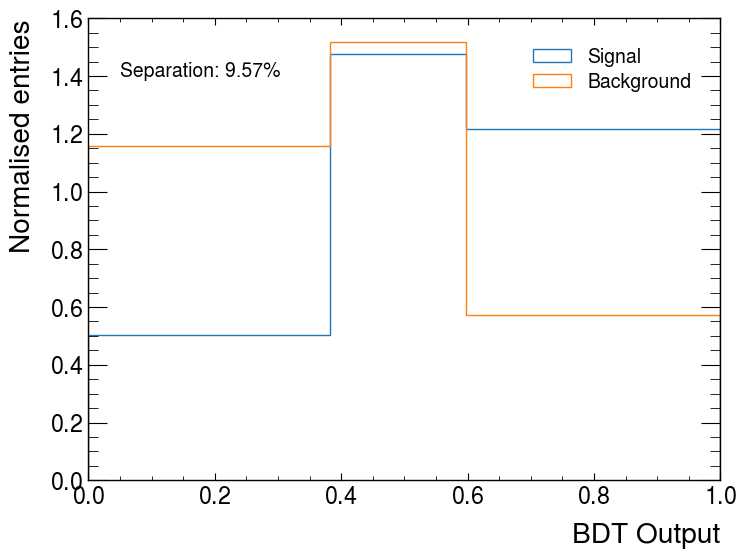

In [130]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig, weights=df_sig_70['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg, weights=df_bkg_70['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.4, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


Features with Average Importance (Descending):
Feature Name: jet_tagWeightBin_DL1r_Continuous_Max, Average Importance: 0.2692776173353195
Feature Name: ph_conversion_type[:,0], Average Importance: 0.1496608667075634
Feature Name: ph_conversion_type[:,1], Average Importance: 0.1202197726815939
Feature Name: event_nbjets85, Average Importance: 0.06763366423547268
Feature Name: ph_mlph_closest[:,1], Average Importance: 0.04371214844286442
Feature Name: dr_lep_ph1, Average Importance: 0.04109238367527723
Feature Name: dr_lep_ph0, Average Importance: 0.030040837358683348
Feature Name: ph_eta[:,1], Average Importance: 0.029106114991009235
Feature Name: jet_pt[:,0], Average Importance: 0.026043419260531664
Feature Name: jet_pt[:,1], Average Importance: 0.02379255974665284
Feature Name: m_AllObjects, Average Importance: 0.02296188846230507
Feature Name: ph_mphb85_closest[:,0], Average Importance: 0.021712809335440397
Feature Name: ph_mphb85_closest[:,1], Average Importance: 0.02138970140367746

<Figure size 1200x800 with 0 Axes>

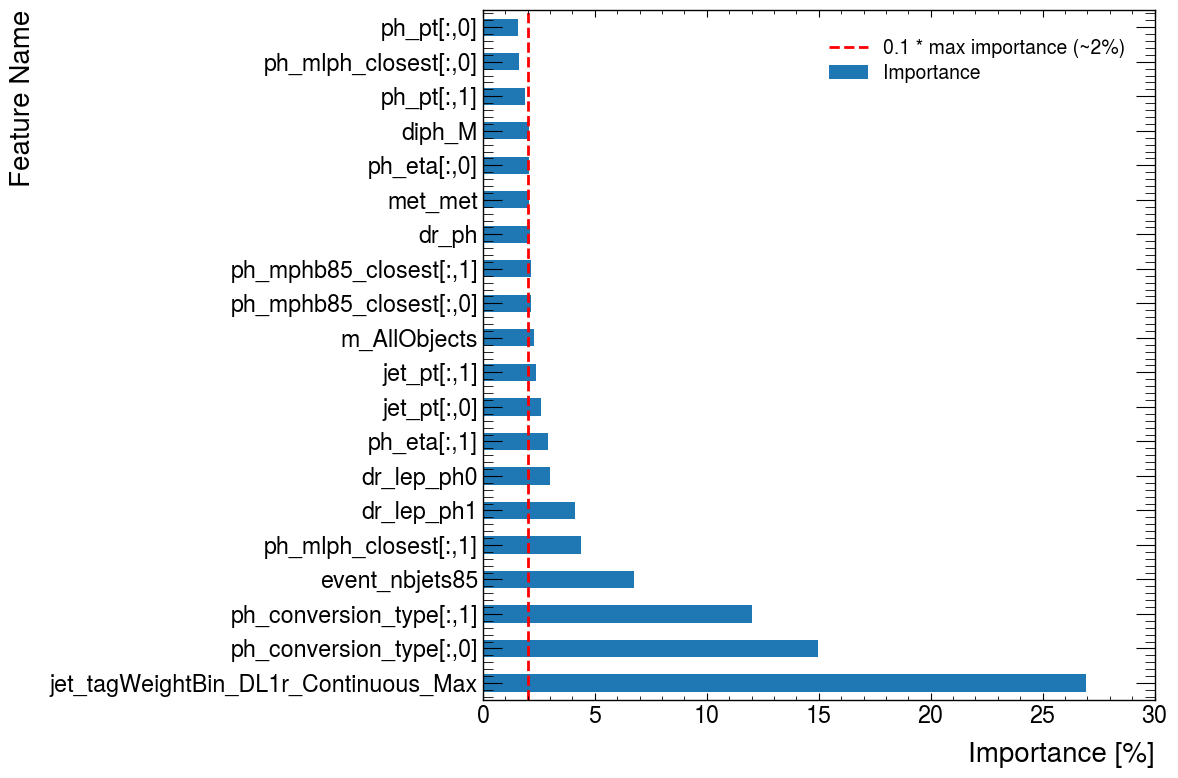

In [96]:
import matplotlib.pyplot as plt
import pandas as pd

def average_feature_importances(models, feature_cols):
  """
  This function calculates the average importance for each feature across all folds/models.

  Args:
      models: A list of XGBoost classifier models.
      feature_cols: A list of feature column names.

  Returns:
      A dictionary containing feature name and its average importance across all folds.
  """
  # Initialize a dictionary to store average importance
  average_importances = {feature: 0.0 for feature in feature_cols}

  # Iterate through each model and accumulate importance for each feature
  for model in models:
    importance_scores = model.feature_importances_  # Access feature importance attribute
    for feature, importance in zip(feature_cols, importance_scores):
      average_importances[feature] += importance

  # Calculate average importance by dividing by the total number of models
  num_models = len(models)
  for feature in average_importances:
    average_importances[feature] /= num_models

  # Sort features by importance in descending order
  sorted_importances = sorted(average_importances.items(), key=lambda x: x[1], reverse=True)
  return sorted_importances

# Assuming models and feature_cols are available (replace with your actual data)
average_importances = average_feature_importances(models, feature_cols)

# Print features with average importance (sorted by descending importance)
print("Features with Average Importance (Descending):")
for feature, importance in average_importances:
  print(f"Feature Name: {feature}, Average Importance: {importance}")

# Create DataFrame from sorted importance and plot as horizontal bar chart
importance_df = pd.DataFrame(average_importances, columns=['Feature', 'Importance'])
importance_df['Importance'] *= 100  # Scale importance to percentage

plt.figure(figsize=(12, 8))
importance_df.set_index('Feature').plot.barh(legend=False, figsize=(12, 8))
plt.xlabel('Importance [%]', fontsize=20)
plt.ylabel('Feature Name', fontsize=20)

# Optional: Add a threshold line (adjust threshold value as needed)
plt.axvline(2.0, color='red', linestyle='--', label='0.1 * max importance (~2%)')
plt.legend()
#plt.savefig(f'Feature_importance_average_Model6.pdf')

plt.tight_layout()
plt.show()


sig histogram values:  [0.02479414 0.33228875 0.72221242 1.05689471 1.36572973 1.64305581
 1.82695848 1.77571942 1.13848961 0.11385697]
bkg histogram values:  [0.26478934 1.45601766 1.52518357 1.44148654 1.36708396 1.67284443
 1.19055341 0.70604384 0.32891623 0.04708079]


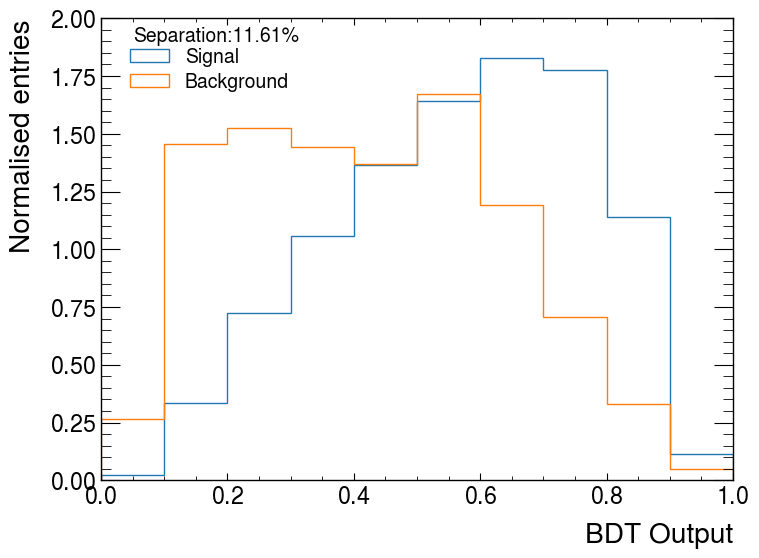

In [90]:
# Considering Negative Weights

bc_sig,_,_ = plt.hist(results_sig, weights=(df_sig_70['weight']),  range=(0,1), bins=nbins, histtype='step', density=True, label='Signal')
bc_bkg,_,_ = plt.hist(results_bkg, weights=(df_bkg_70['weight']), range=(0,1), bins=nbins, histtype='step', density=True, label='Background')
print('sig histogram values: ',bc_sig )
print('bkg histogram values: ',bc_bkg )

separation = 0.5 * np.sum(np.nan_to_num(((bc_sig/nbins - bc_bkg/nbins) ** 2) / (bc_sig/nbins + bc_bkg/nbins)))

plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
#mplhep.atlas.label('WIP', data=False, ax=ax)
plt.text(x=0.05, y=1.9,s=F'Separation:{separation*100:.2f}%')
#plt.savefig(f'separation.pdf')
plt.legend()

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

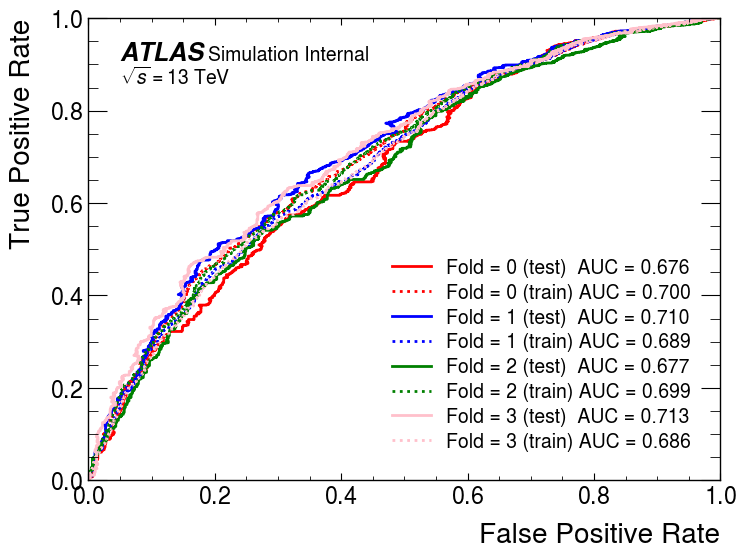

In [101]:
nfolds = 4
#fig, axes = plt.subplots(nrows=2,ncols=2, figsize=(12,10))
#axes = axes.reshape(-1)
colors = ['red','blue','green','pink'] 
for fold in range(nfolds):
    results_sig_fold_test = results_sig[df_sig_70['eventNumber']%folds == fold]
    results_bkg_fold_test = results_bkg[df_bkg_70['eventNumber']%folds == fold]
    weights_sig_fold_test = df_sig_70['weight'][df_sig_70['eventNumber']%folds == fold]
    weights_bkg_fold_test = df_bkg_70['weight'][df_bkg_70['eventNumber']%folds == fold]
    y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
    scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
    weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, sample_weight=weights,pos_label=1)
    #AUC = metrics.roc_auc_score(y, scores)
    AUC = trapezoid(y=tpr,x=fpr)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (test)  AUC = {AUC:.3f}', color=colors[fold])
    
    results_sig_fold_train = results_sig[df_sig_70['eventNumber']%folds != fold]
    results_bkg_fold_train = results_bkg[df_bkg_70['eventNumber']%folds != fold]
    weights_sig_fold_train = df_sig_70['weight'][df_sig_70['eventNumber']%folds != fold]
    weights_bkg_fold_train = df_bkg_70['weight'][df_bkg_70['eventNumber']%folds != fold]
    y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
    scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
    weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, sample_weight=weights, pos_label=1)
    AUC = trapezoid(y=tpr,x=fpr)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (train) AUC = {AUC:.3f}', color=colors[fold], linestyle='dotted')

plt.legend()
plt.xlim(0,1)
plt.ylim(0,1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)   # true to remove Simulation
#plt.savefig(f'auc.pdf')




(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

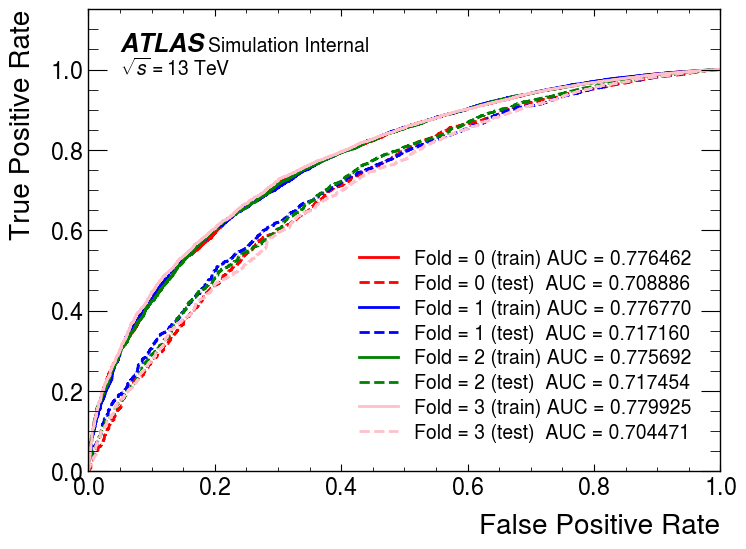

In [100]:

for fold in range(nfolds):
    X_sig_train = df_sig_70[feature_cols][df_sig_70['eventNumber']%nfolds != fold]
    X_sig_test = df_sig_70[feature_cols][df_sig_70['eventNumber']%nfolds == fold]
    X_bkg_train = df_bkg_70[feature_cols][df_bkg_70['eventNumber']%nfolds != fold]
    X_bkg_test = df_bkg_70[feature_cols][df_bkg_70['eventNumber']%nfolds == fold]
    results_sig_fold_train = models[fold].predict_proba(X_sig_train)[:,1]
    results_bkg_fold_train = models[fold].predict_proba(X_bkg_train)[:,1]
    results_sig_fold_test = models[fold].predict_proba(X_sig_test)[:,1]
    results_bkg_fold_test = models[fold].predict_proba(X_bkg_test)[:,1]

    y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
    scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
    AUC = metrics.roc_auc_score(y, scores)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (train) AUC = {AUC:.6f}', color=colors[fold])
    
    y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
    scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
    fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
    AUC = metrics.roc_auc_score(y, scores)
    plt.plot(fpr,tpr,label=F'Fold = {fold} (test)  AUC = {AUC:.6f}', color=colors[fold], linestyle='--')

plt.legend()
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)
#plt.savefig('auc.png')

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

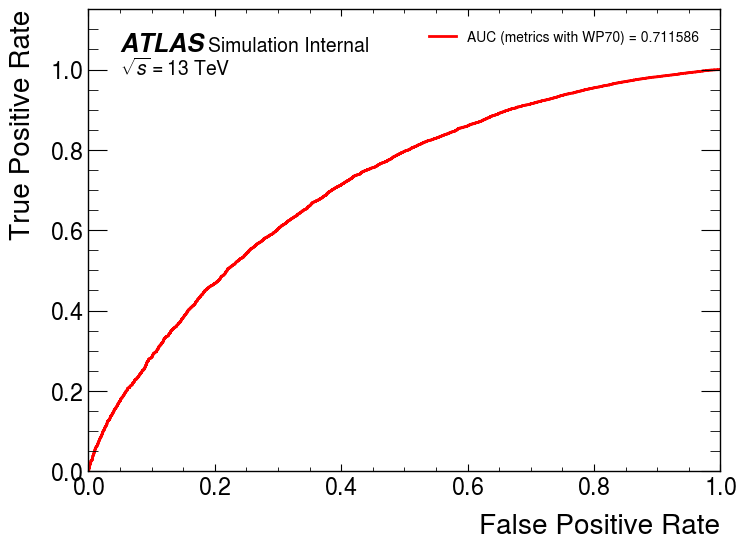

In [131]:
# Aggregate AUC 

scores = np.concatenate([results_sig, results_bkg])
y = np.concatenate([np.ones_like(results_sig), np.zeros_like(results_bkg)])

fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
AUC = metrics.roc_auc_score(y, scores)

plt.plot(fpr,tpr,label=F'AUC (metrics with WP70) = {AUC:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

In [120]:
# WP85 training and evaluated with WP85 dataset as well

In [123]:
X_sig = df_sig[feature_cols].to_numpy().astype(np.float32) 
X_bkg = df_bkg[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = [model.predict_proba(X_sig)[:,1] for model in models]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg)[:,1] for model in models]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig_85 = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_85 = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig_85, results_bkg_85
print("Length sig: ", len(results_sig_85))
print("Length bkg: ", len(results_bkg_85))

Arrays for BDT scroes:
Sig:  [array([0.51949185, 0.6383609 , 0.7180131 , ..., 0.7339629 , 0.7771796 ,
       0.5389605 ], dtype=float32), array([0.56396633, 0.5911795 , 0.7326335 , ..., 0.72809094, 0.7195093 ,
       0.46064162], dtype=float32), array([0.48828992, 0.6955217 , 0.6916631 , ..., 0.76824546, 0.6183214 ,
       0.6238853 ], dtype=float32), array([0.46608007, 0.5842363 , 0.6919366 , ..., 0.7256135 , 0.7530754 ,
       0.6193473 ], dtype=float32)]
Bkg:  [array([0.3583942 , 0.49710447, 0.79023635, ..., 0.15175329, 0.43322104,
       0.10948578], dtype=float32), array([0.32352176, 0.46794915, 0.72822434, ..., 0.15816088, 0.62862676,
       0.11445035], dtype=float32), array([0.29478496, 0.584455  , 0.62510806, ..., 0.14986554, 0.44511864,
       0.1104516 ], dtype=float32), array([0.27803603, 0.6139644 , 0.77051574, ..., 0.2322155 , 0.50655186,
       0.0940142 ], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  358887
Length bkg:  5855


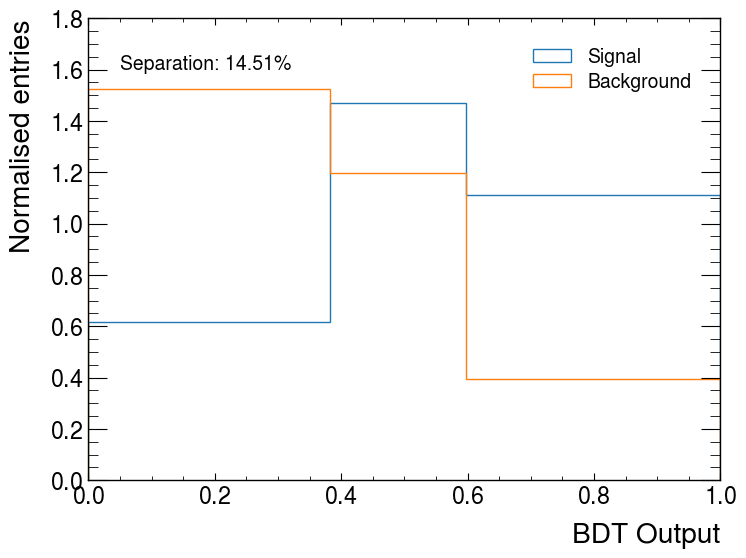

In [124]:

# Define custom bin edges
custom_bins = [0, 0.383, 0.598, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig_85, weights=df_sig['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg_85, weights=df_bkg['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

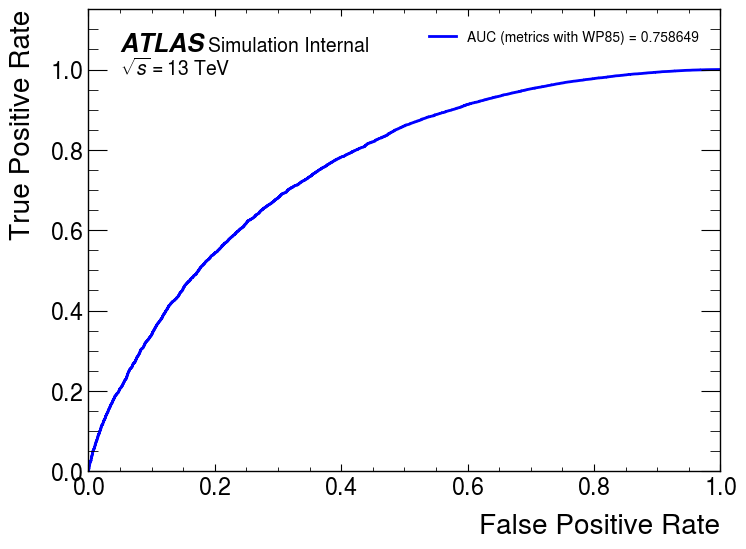

In [126]:
# Aggregate AUC 

scores = np.concatenate([results_sig_85, results_bkg_85])
y = np.concatenate([np.ones_like(results_sig_85), np.zeros_like(results_bkg_85)])

fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
AUC_85 = metrics.roc_auc_score(y, scores)

plt.plot(fpr,tpr,label=F'AUC (metrics with WP85) = {AUC_85:.6f}', color='blue')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

In [136]:
data = np.load('roc_data.npz')
fpr_70 = data['fpr']
tpr_70 = data['tpr']
thresholds_70 = data['thresholds']
AUC_70 = data['auc']
print(f"Loaded data: AUC = {AUC_70}")

Loaded data: AUC = 0.6948133504263093


0.7115856692100513


(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

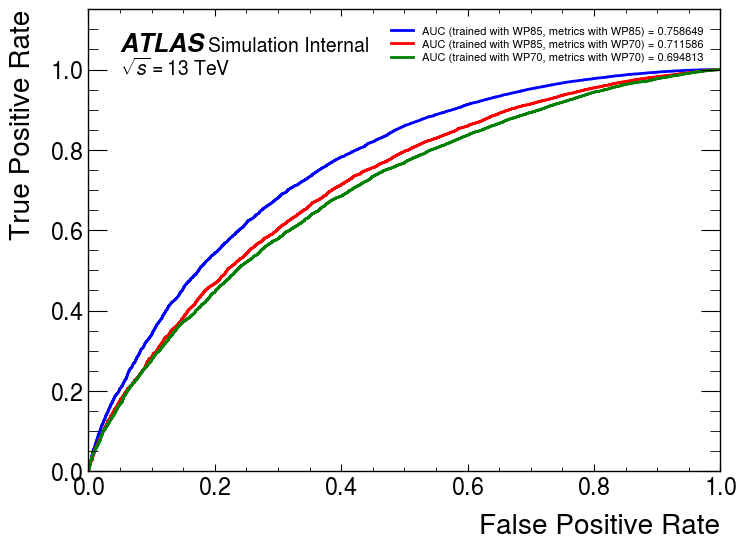

In [138]:
# AUC's comparison:

scores = np.concatenate([results_sig, results_bkg])
y = np.concatenate([np.ones_like(results_sig), np.zeros_like(results_bkg)])

fpr, tpr, thresholds = metrics.roc_curve(y, scores, pos_label=1)
AUC = metrics.roc_auc_score(y, scores)

print(AUC)
scores = np.concatenate([results_sig_85, results_bkg_85])
y = np.concatenate([np.ones_like(results_sig_85), np.zeros_like(results_bkg_85)])

fpr_85, tpr_85, thresholds_85 = metrics.roc_curve(y, scores, pos_label=1)
AUC_85 = metrics.roc_auc_score(y, scores)



plt.plot(fpr_85,tpr_85,label=F'AUC (trained with WP85, metrics with WP85) = {AUC_85:.6f}', color='blue')
plt.plot(fpr,tpr,label=F'AUC (trained with WP85, metrics with WP70) = {AUC:.6f}', color='red')
plt.plot(fpr_70,tpr_70,label=F'AUC (trained with WP70, metrics with WP70) = {AUC_70:.6f}', color='green')


plt.legend(loc = 'upper right', fontsize=8)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

In [139]:
# Statistics - Retuning


In [ ]:
df_bkg_prompt_tot_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model//ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_tty_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model//ntuples_WP85/*ttgamma_*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_Vyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_tot_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model//ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_tty_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model//ntuples_WP85/*ttgamma_*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_Vyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)


In [18]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

-----------------------------------------------
0.014645075530021394 1.8770936772715483
0.015106752828460074 1.8361208721682907
11 10 10
Signal train histogram: [0.01464508 0.31006156 0.74308335 1.09724549 1.43278289 1.72301022
 1.87709368 1.75384194 0.97195729 0.07627825]
Signal test histogram: [0.01510675 0.31137874 0.72804318 1.05451574 1.37323293 1.66647587
 1.83612087 1.80306716 1.10016492 0.11189455]
Background train histogram: [0.16756168 1.06139305 1.52446508 1.95959981 1.28163567 1.65553919
 1.2643128  0.80798289 0.25712587 0.02038394]
Background test histogram: [0.22675927 1.3444948  1.52655577 1.45559231 1.42093867 1.79591505
 1.16204401 0.76148706 0.24314818 0.06306464]
-----------------------------------------------

Signal train errors: [0.00248837 0.0114624  0.01773029 0.02152934 0.02460264 0.02697995
 0.02814778 0.02716127 0.02016555 0.00561012]
Signal test errors: [0.0014617  0.00666326 0.01014176 0.01220929 0.01393853 0.01534391
 0.01607012 0.01592143 0.01238464 0.003

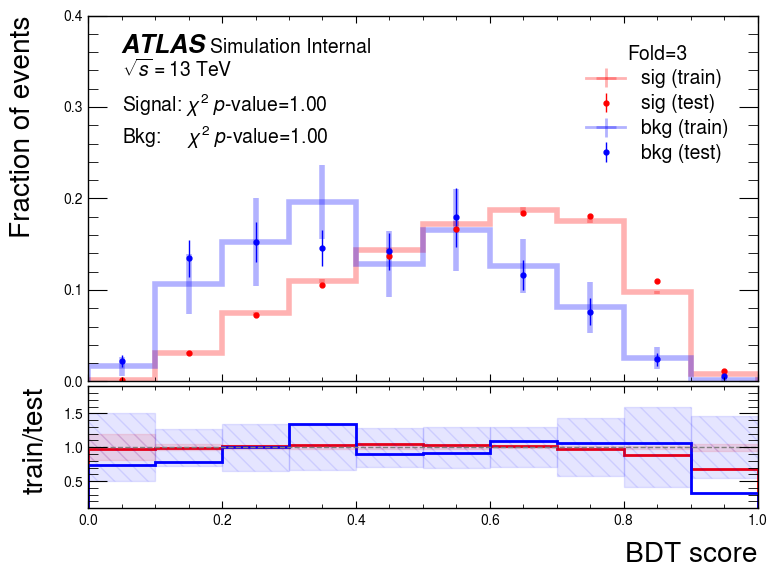

In [30]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model6.png')

-----------------------------------------------
0.01931229447731529 1.8959023387001108
0.016574754074264623 1.8607187363990665
11 10 10
Signal train histogram: [0.01931229 0.32178727 0.72649245 1.08095024 1.41740121 1.69483135
 1.89590234 1.76990752 0.98436045 0.089056  ]
Signal test histogram: [0.01657475 0.30572732 0.70210373 1.06038814 1.36895129 1.67656819
 1.86071874 1.78776958 1.10885755 0.11234126]
Background train histogram: [0.19918339 1.23048696 1.46905332 1.73987945 1.51284141 1.67765484
 1.04176167 0.84738858 0.27090576 0.01084369]
Background test histogram: [0.26477508 1.21540844 1.45807191 1.45716602 1.65390791 1.74019219
 1.19914826 0.85843215 0.14154079 0.01135688]
-----------------------------------------------

Signal train errors: [0.00287481 0.01168326 0.01752046 0.02137167 0.0244995  0.02674093
 0.02827907 0.02728252 0.0202905  0.00610656]
Signal test errors: [0.00152735 0.00658533 0.00998464 0.01225513 0.01390393 0.01540489
 0.01616706 0.01583384 0.01244059 0.0039

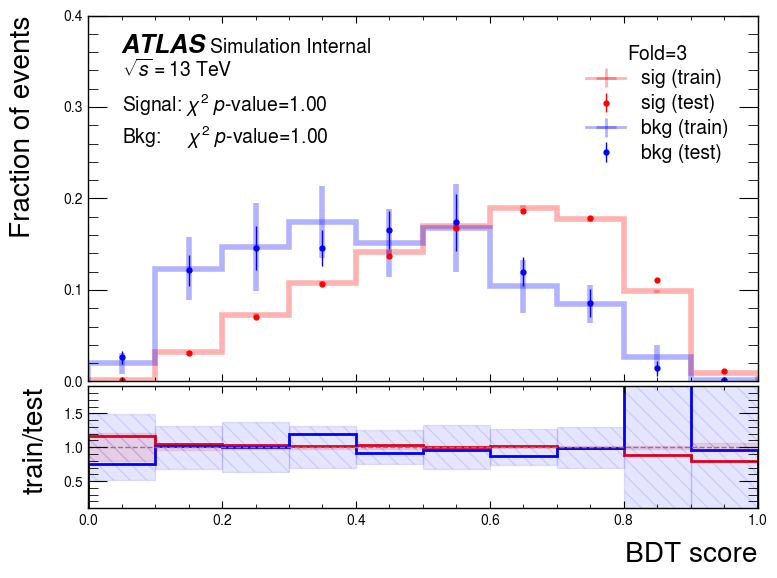

In [25]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)


# Example dummy data and plots:
results_sig_fold_test = results_sig[df_sig['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg[df_bkg['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig['weight'][df_sig['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg['weight'][df_bkg['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig[df_sig['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg[df_bkg['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig['weight'][df_sig['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg['weight'][df_bkg['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}.png')

In [19]:
len(results_sig_fold_train)

NameError: name 'results_sig_fold_train' is not defined

In [20]:
bkg_corr_matrix = df_bkg[feature_cols].corr()
sig_corr_matrix = df_sig[feature_cols].corr()

#bkg_corr_matrix.to_csv('bkg_correlation_matrix.csv', index=True)  # Save to CSV


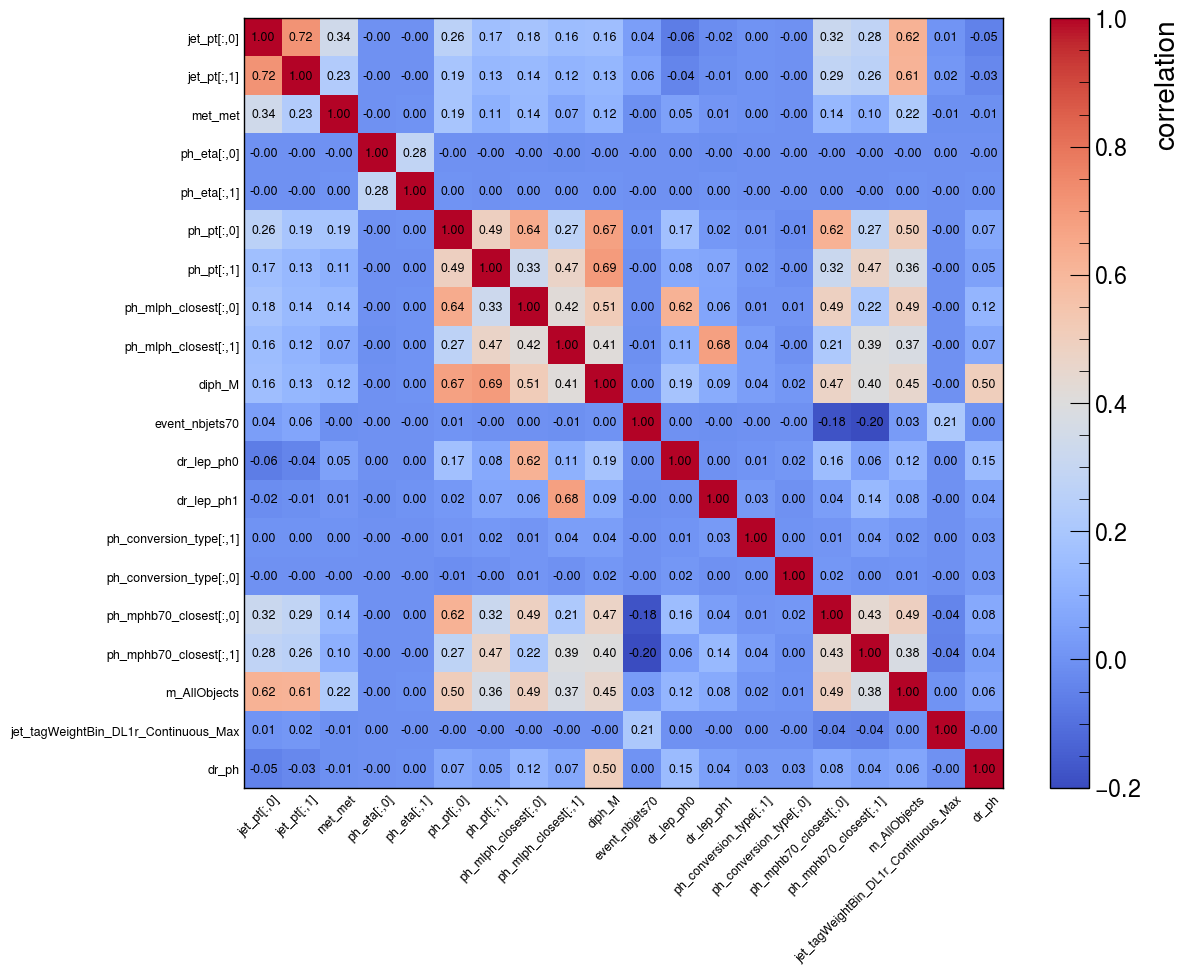

In [23]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = sig_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

plt.savefig('sig_correlation_heatmap_seaborn_large_white_Model6.png', dpi=500, bbox_inches='tight')


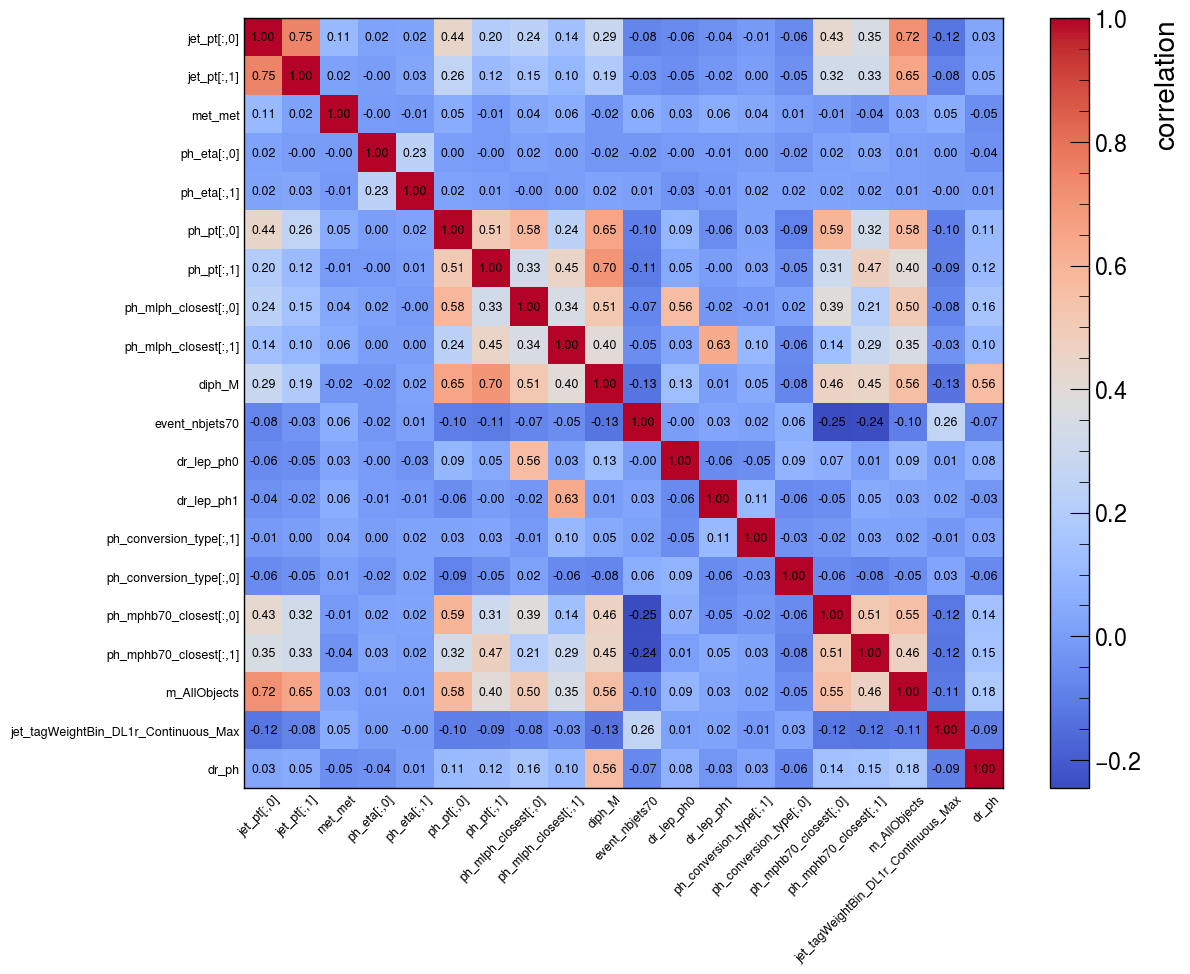

In [24]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = bkg_corr_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides


plt.savefig('bkg_correlation_heatmap_seaborn_large_white_Model6.png', dpi=500, bbox_inches='tight')



In [45]:
print(len(corr))

5


In [32]:
xgboost.__version__

'2.0.2'